# EduPredict AI — Day 4: Deep Learning using TensorFlow & Keras

**Goal:** Build and evaluate four separate **Sequential Neural Networks** (MLP regressors) to predict final student grade (`G3`, `0–20`) across:
1. Mathematics — Early Prediction (no `G1`, `G2`)
2. Mathematics — Late Prediction (with `G1`, `G2`)
3. Portuguese — Early Prediction (no `G1`, `G2`)
4. Portuguese — Late Prediction (with `G1`, `G2`)

**Architecture (Exact Specification):**
`Input` → `Dense(64, relu)` → `Dense(32, relu)` → `Dense(16, relu)` → `Dense(1, linear)`

**Training Rules:**
- Same `80/20` train-test split (`random_state=42`) as Day 3.
- Preprocessing (`StandardScaler` + `OneHotEncoder`) is fit **strictly on the training subset** (`X_train`) — never on validation or unseen test data.
- Compiled with `Adam`, `loss='mse'`, `metrics=['mae']`.
- Trained for up to `150` epochs with `EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)`.
- Compared fairly against Day 3's best Scikit-learn models on unseen test metrics (`MAE`, `RMSE`, `R2`).

## 1. Setup and Imports

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras

from keras import Input, Sequential
from keras.callbacks import EarlyStopping
from keras.layers import Dense
from keras.optimizers import Adam
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", context="notebook")

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
RAW_DIR = PROJECT_ROOT / "data" / "raw"
MODELS_DIR = PROJECT_ROOT / "models"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
FIGURES_DIR = ARTIFACTS_DIR / "figures"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
MAX_EPOCHS = 150

print(f"TensorFlow: {tf.__version__} | Keras: {keras.__version__}")
print(f"Project root: {PROJECT_ROOT}")

TensorFlow: 2.21.0 | Keras: 3.15.1
Project root: <project-root>


## 2. Modular Preprocessing, Splitting & Neural Network Builder
To guarantee zero data leakage:
1. `split_data_zero_leakage` first creates the exact same `80/20` train-test split (`random_state=42`) as Day 3, keeping `X_test` completely untouched.
2. It then splits the `80%` training pool into `80%` train (`X_train`) and `20%` validation (`X_val`) for `EarlyStopping`.
3. `ColumnTransformer` (`StandardScaler` + `OneHotEncoder(sparse_output=False, handle_unknown='ignore')`) is **fit only on `X_train`**, then applied with `.transform()` to `X_val` and `X_test`.

In [2]:
def load_raw_dataset(filename: str) -> pd.DataFrame:
    """Load original UCI CSV read-only."""
    return pd.read_csv(RAW_DIR / filename, sep=";")


def split_data_zero_leakage(df: pd.DataFrame, scenario: str, random_state: int = RANDOM_STATE):
    """Create Day 3 test split (20%) and split remaining 80% into train/validation."""
    drop_cols = ["G1", "G2", "G3"] if scenario == "early" else ["G3"]
    X = df.drop(columns=drop_cols).copy()
    y = df["G3"].to_numpy(dtype=np.float32)

    # Exact same test split as Day 3
    X_train_full, X_test, y_train_full, y_test = train_test_split(
        X, y, test_size=0.2, random_state=random_state
    )

    # Validation split strictly from training pool so EarlyStopping never sees test data
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full, test_size=0.2, random_state=random_state
    )

    # Leakage assertions
    assert "G3" not in X.columns
    if scenario == "early":
        assert "G1" not in X.columns and "G2" not in X.columns
    assert set(X_train.index).isdisjoint(set(X_test.index))
    assert set(X_val.index).isdisjoint(set(X_test.index))
    assert set(X_train.index).isdisjoint(set(X_val.index))

    return X_train, X_val, X_test, y_train, y_val, y_test


def fit_transform_features(X_train: pd.DataFrame, X_val: pd.DataFrame, X_test: pd.DataFrame):
    """Fit ColumnTransformer strictly on X_train and return dense float32 arrays."""
    num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ]
    )

    X_train_arr = preprocessor.fit_transform(X_train).astype(np.float32)
    X_val_arr = preprocessor.transform(X_val).astype(np.float32)
    X_test_arr = preprocessor.transform(X_test).astype(np.float32)
    return preprocessor, X_train_arr, X_val_arr, X_test_arr


def build_student_nn(input_dim: int) -> Sequential:
    """Build the Sequential MLP: Input -> 64 -> 32 -> 16 -> 1 (linear)."""
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(64, activation="relu"),
        Dense(32, activation="relu"),
        Dense(16, activation="relu"),
        Dense(1, activation="linear"),
    ])
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"],
    )
    return model


def regression_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    """Compute MAE, RMSE, and R2."""
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(root_mean_squared_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }

## 3. Train All Four Neural Networks (Max 150 Epochs + EarlyStopping)
We set `tf.keras.utils.set_random_seed(42)` before building each network for reproducibility, train with `EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)`, and record Train, Validation, and Test metrics.

In [3]:
datasets = {
    "Mathematics": load_raw_dataset("student-mat.csv"),
    "Portuguese": load_raw_dataset("student-por.csv"),
}

dl_records = []
histories = {}
artifacts_store = {}

for subject_name, df in datasets.items():
    for scenario_key in ["early", "late"]:
        tf.keras.utils.set_random_seed(RANDOM_STATE)

        X_train, X_val, X_test, y_train, y_val, y_test = split_data_zero_leakage(df, scenario_key)
        preprocessor, X_tr_arr, X_val_arr, X_te_arr = fit_transform_features(X_train, X_val, X_test)

        model = build_student_nn(input_dim=X_tr_arr.shape[1])
        early_stop = EarlyStopping(
            monitor="val_loss",
            patience=15,
            restore_best_weights=True,
        )

        history = model.fit(
            X_tr_arr, y_train,
            validation_data=(X_val_arr, y_val),
            epochs=MAX_EPOCHS,
            batch_size=16,
            callbacks=[early_stop],
            verbose=0,
        )

        val_losses = history.history["val_loss"]
        best_epoch = int(np.argmin(val_losses)) + 1
        epochs_run = len(val_losses)

        train_pred = model.predict(X_tr_arr, verbose=0).ravel()
        val_pred = model.predict(X_val_arr, verbose=0).ravel()
        test_pred = model.predict(X_te_arr, verbose=0).ravel()

        tr_m = regression_metrics(y_train, train_pred)
        va_m = regression_metrics(y_val, val_pred)
        te_m = regression_metrics(y_test, test_pred)

        dl_records.append({
            "Subject": subject_name,
            "Scenario": scenario_key,
            "Input_Dim": X_tr_arr.shape[1],
            "Epochs_Run": epochs_run,
            "Best_Epoch": best_epoch,
            "Train_MAE": tr_m["MAE"],
            "Train_RMSE": tr_m["RMSE"],
            "Train_R2": tr_m["R2"],
            "Val_MAE": va_m["MAE"],
            "Val_RMSE": va_m["RMSE"],
            "Val_R2": va_m["R2"],
            "Test_MAE": te_m["MAE"],
            "Test_RMSE": te_m["RMSE"],
            "Test_R2": te_m["R2"],
        })

        histories[(subject_name, scenario_key)] = {
            "history": history.history,
            "best_epoch": best_epoch,
        }
        artifacts_store[(subject_name, scenario_key)] = {
            "model": model,
            "preprocessor": preprocessor,
            "X_test": X_test,
            "y_test": y_test,
            "test_pred": test_pred,
            "feature_columns": list(X_train.columns),
        }

        print(
            f"[Trained] {subject_name} ({scenario_key}) | input_dim={X_tr_arr.shape[1]} | "
            f"best_epoch={best_epoch}/{epochs_run} | "
            f"Test MAE={te_m['MAE']:.4f}, RMSE={te_m['RMSE']:.4f}, R2={te_m['R2']:.4f}"
        )

dl_results_df = pd.DataFrame(dl_records)
display(dl_results_df.round(4))

[Trained] Mathematics (early) | input_dim=56 | best_epoch=5/20 | Test MAE=3.4899, RMSE=4.4397, R2=0.0387


[Trained] Mathematics (late) | input_dim=58 | best_epoch=22/37 | Test MAE=1.8380, RMSE=2.4890, R2=0.6979


[Trained] Portuguese (early) | input_dim=56 | best_epoch=14/29 | Test MAE=2.0679, RMSE=2.8165, R2=0.1865


[Trained] Portuguese (late) | input_dim=58 | best_epoch=20/35 | Test MAE=0.9147, RMSE=1.3043, R2=0.8255


,Subject,Scenario,Input_Dim,Epochs_Run,Best_Epoch,Train_MAE,Train_RMSE,Train_R2,Val_MAE,Val_RMSE,Val_R2,Test_MAE,Test_RMSE,Test_R2
0,Mathematics,early,56,20,5,3.3080,4.3399,0.1571,2.6653,3.8546,-0.0348,3.4899,4.4397,0.0387
1,Mathematics,late,58,37,22,0.9739,1.3599,0.9172,1.2652,1.6393,0.8128,1.8380,2.4890,0.6979
2,Portuguese,early,56,29,14,1.6770,2.3532,0.4993,1.8070,2.3805,0.3217,2.0679,2.8165,0.1865
3,Portuguese,late,58,35,20,0.6894,1.0341,0.9033,0.8609,1.1401,0.8444,0.9147,1.3043,0.8255


In [4]:
# Print Keras architecture summary for one Early and one Late model
print("=== Neural Network Architecture (Mathematics Early) ===")
artifacts_store[("Mathematics", "early")]["model"].summary()

=== Neural Network Architecture (Mathematics Early) ===


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,821 (73.52 KB)

 Trainable params: 6,273 (24.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 12,548 (49.02 KB)

## 4. Compare Deep Learning vs Day 3 Best Scikit-learn Models
We load Day 3's saved test evaluation summary (`artifacts/ml_best_models_summary.json`) so we compare both paradigms fairly on the exact same unseen test split (`random_state=42`).

In [5]:
ml_best = json.loads((ARTIFACTS_DIR / "ml_best_models_summary.json").read_text())
ml_best_df = pd.DataFrame(ml_best).rename(columns={
    "subject": "Subject",
    "scenario": "Scenario",
    "selected_model": "Best_ML_Model",
    "test_mae": "ML_Test_MAE",
    "test_rmse": "ML_Test_RMSE",
    "test_r2": "ML_Test_R2",
})

comparison_df = pd.merge(
    dl_results_df[["Subject", "Scenario", "Test_MAE", "Test_RMSE", "Test_R2"]].rename(columns={
        "Test_MAE": "DL_Test_MAE",
        "Test_RMSE": "DL_Test_RMSE",
        "Test_R2": "DL_Test_R2",
    }),
    ml_best_df[["Subject", "Scenario", "Best_ML_Model", "ML_Test_MAE", "ML_Test_RMSE", "ML_Test_R2"]],
    on=["Subject", "Scenario"]
)

comparison_df["RMSE_Diff (DL - ML)"] = comparison_df["DL_Test_RMSE"] - comparison_df["ML_Test_RMSE"]
comparison_df["Winner_by_Test_RMSE"] = np.where(
    comparison_df["DL_Test_RMSE"] < comparison_df["ML_Test_RMSE"],
    "Keras Neural Network",
    comparison_df["Best_ML_Model"] + " (Day 3 ML)"
)

print("=== Deep Learning (Keras) vs Best Scikit-learn Models (Unseen Test Set) ===")
display(comparison_df.round(4))

=== Deep Learning (Keras) vs Best Scikit-learn Models (Unseen Test Set) ===


,Subject,Scenario,DL_Test_MAE,DL_Test_RMSE,DL_Test_R2,Best_ML_Model,ML_Test_MAE,ML_Test_RMSE,ML_Test_R2,RMSE_Diff (DL - ML),Winner_by_Test_RMSE
0,Mathematics,early,3.4899,4.4397,0.0387,Random Forest Regressor,2.9938,3.7508,0.3139,0.6889,Random Forest Regressor (Day 3 ML)
1,Mathematics,late,1.8380,2.4890,0.6979,Random Forest Regressor,1.2005,2.0150,0.8020,0.4740,Random Forest Regressor (Day 3 ML)
2,Portuguese,early,2.0679,2.8165,0.1865,Random Forest Regressor,2.0452,2.8166,0.1865,-0.0001,Keras Neural Network
3,Portuguese,late,0.9147,1.3043,0.8255,Linear Regression,0.7651,1.2149,0.8487,0.0894,Linear Regression (Day 3 ML)


## 5. Visualizations: Training/Validation Loss & DL vs ML Comparison
We generate three diagnostic figures inside `artifacts/figures/`:
1. `12_dl_training_validation_loss.png` — Training Loss (MSE) vs Validation Loss (MSE) across epochs, marking the `EarlyStopping` best epoch.
2. `13_dl_vs_ml_comparison.png` — Side-by-side Test RMSE and Test $R^2$ comparing Keras Neural Networks vs Day 3 Best Scikit-learn models.
3. `14_dl_actual_vs_predicted.png` — Actual vs Predicted `G3` scatter plots on unseen test data.

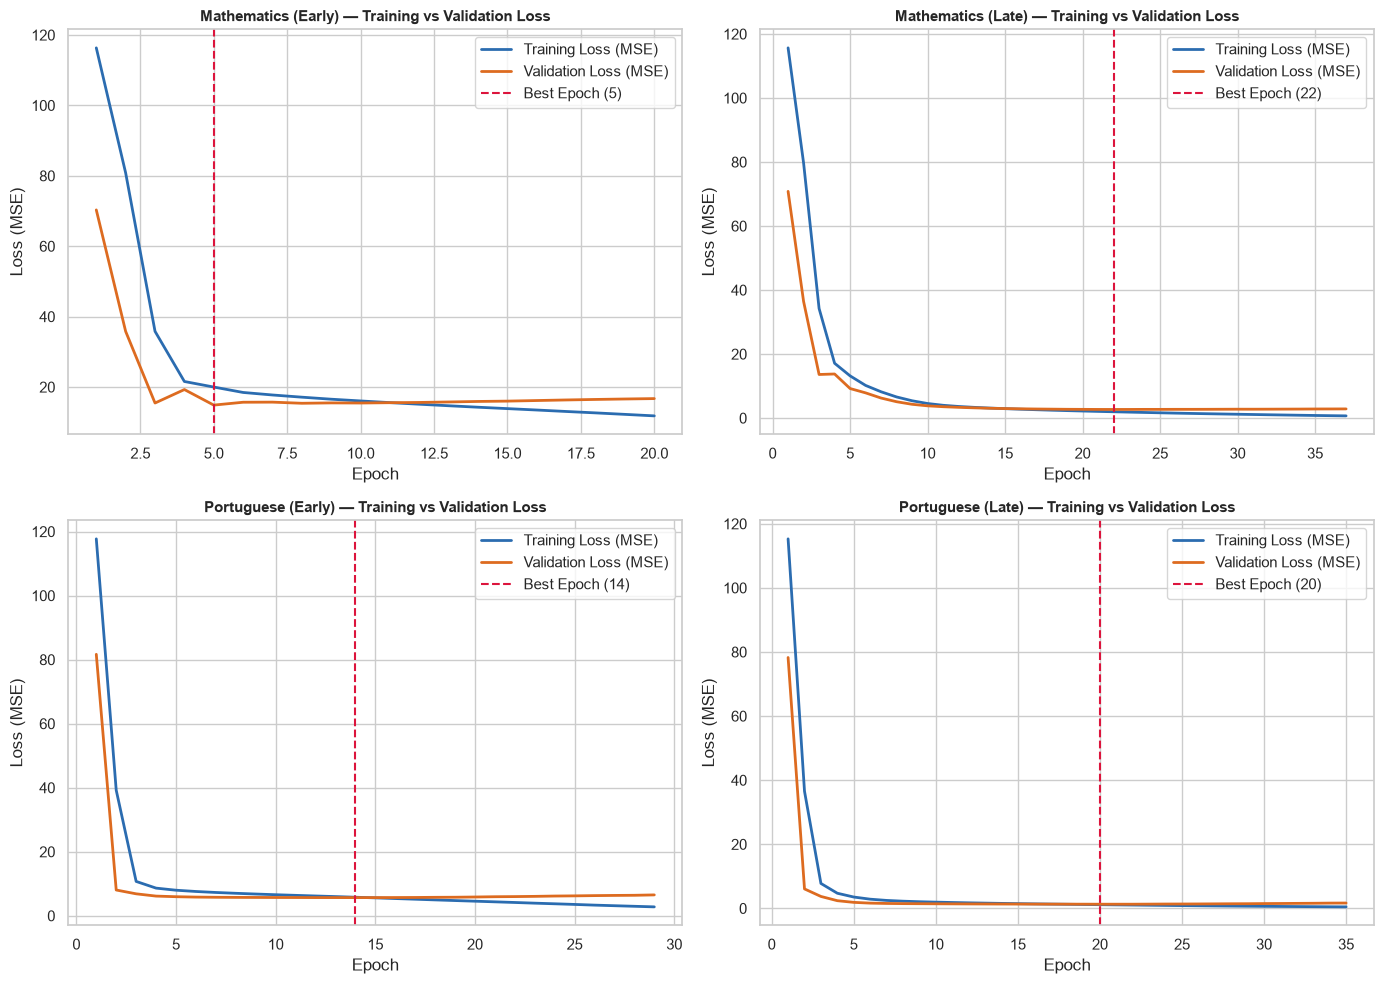

Saved: 12_dl_training_validation_loss.png


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

tasks = [("Mathematics", "early"), ("Mathematics", "late"), ("Portuguese", "early"), ("Portuguese", "late")]
for ax, (subj, scen) in zip(axes, tasks):
    hist = histories[(subj, scen)]["history"]
    best_ep = histories[(subj, scen)]["best_epoch"]
    epochs_range = range(1, len(hist["loss"]) + 1)

    ax.plot(epochs_range, hist["loss"], label="Training Loss (MSE)", color="#2b6cb0", linewidth=2)
    ax.plot(epochs_range, hist["val_loss"], label="Validation Loss (MSE)", color="#dd6b20", linewidth=2)
    ax.axvline(best_ep, color="crimson", linestyle="--", linewidth=1.5, label=f"Best Epoch ({best_ep})")

    ax.set_title(f"{subj} ({scen.title()}) — Training vs Validation Loss", fontsize=11, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss (MSE)")
    ax.legend()

plt.tight_layout()
loss_fig = FIGURES_DIR / "12_dl_training_validation_loss.png"
plt.savefig(loss_fig, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", loss_fig.name)

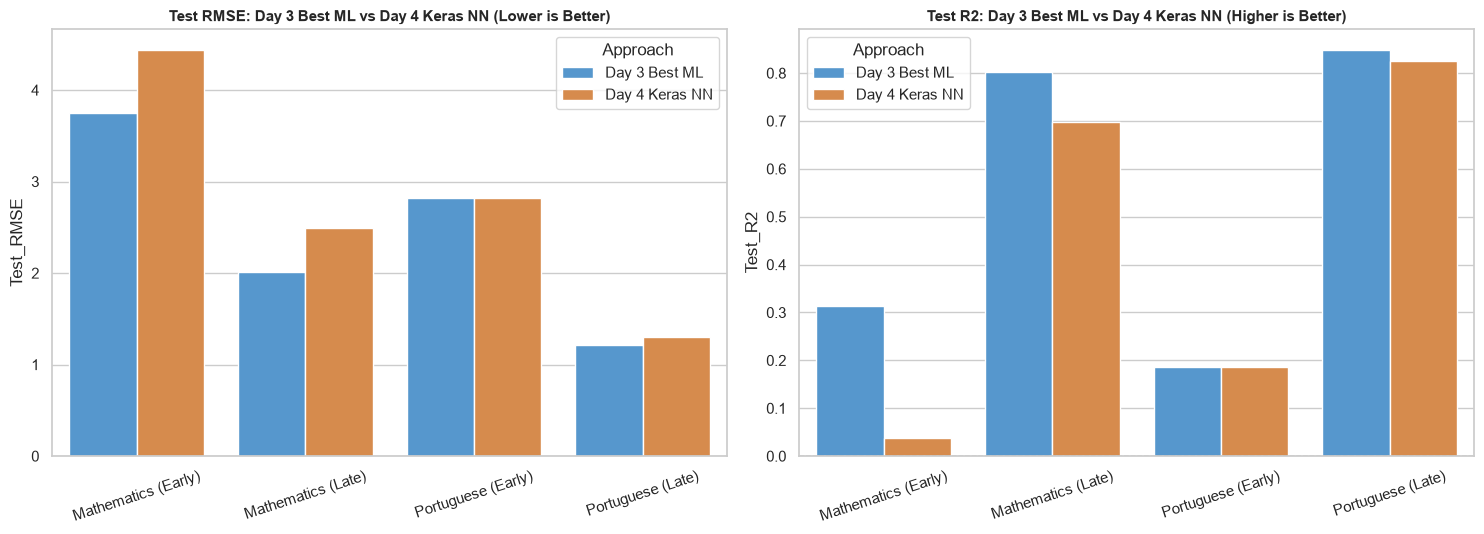

Saved: 13_dl_vs_ml_comparison.png


In [7]:
comparison_df["Task"] = comparison_df["Subject"] + " (" + comparison_df["Scenario"].str.title() + ")"

rmse_melt = comparison_df.melt(
    id_vars="Task", value_vars=["ML_Test_RMSE", "DL_Test_RMSE"],
    var_name="Approach", value_name="Test_RMSE"
).replace({"ML_Test_RMSE": "Day 3 Best ML", "DL_Test_RMSE": "Day 4 Keras NN"})

r2_melt = comparison_df.melt(
    id_vars="Task", value_vars=["ML_Test_R2", "DL_Test_R2"],
    var_name="Approach", value_name="Test_R2"
).replace({"ML_Test_R2": "Day 3 Best ML", "DL_Test_R2": "Day 4 Keras NN"})

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.barplot(data=rmse_melt, x="Task", y="Test_RMSE", hue="Approach", palette=["#4299e1", "#ed8936"], ax=axes[0])
axes[0].set_title("Test RMSE: Day 3 Best ML vs Day 4 Keras NN (Lower is Better)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=18)

sns.barplot(data=r2_melt, x="Task", y="Test_R2", hue="Approach", palette=["#4299e1", "#ed8936"], ax=axes[1])
axes[1].axhline(0, color="black", linestyle="--", linewidth=0.9)
axes[1].set_title("Test R2: Day 3 Best ML vs Day 4 Keras NN (Higher is Better)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=18)

plt.tight_layout()
cmp_fig = FIGURES_DIR / "13_dl_vs_ml_comparison.png"
plt.savefig(cmp_fig, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", cmp_fig.name)

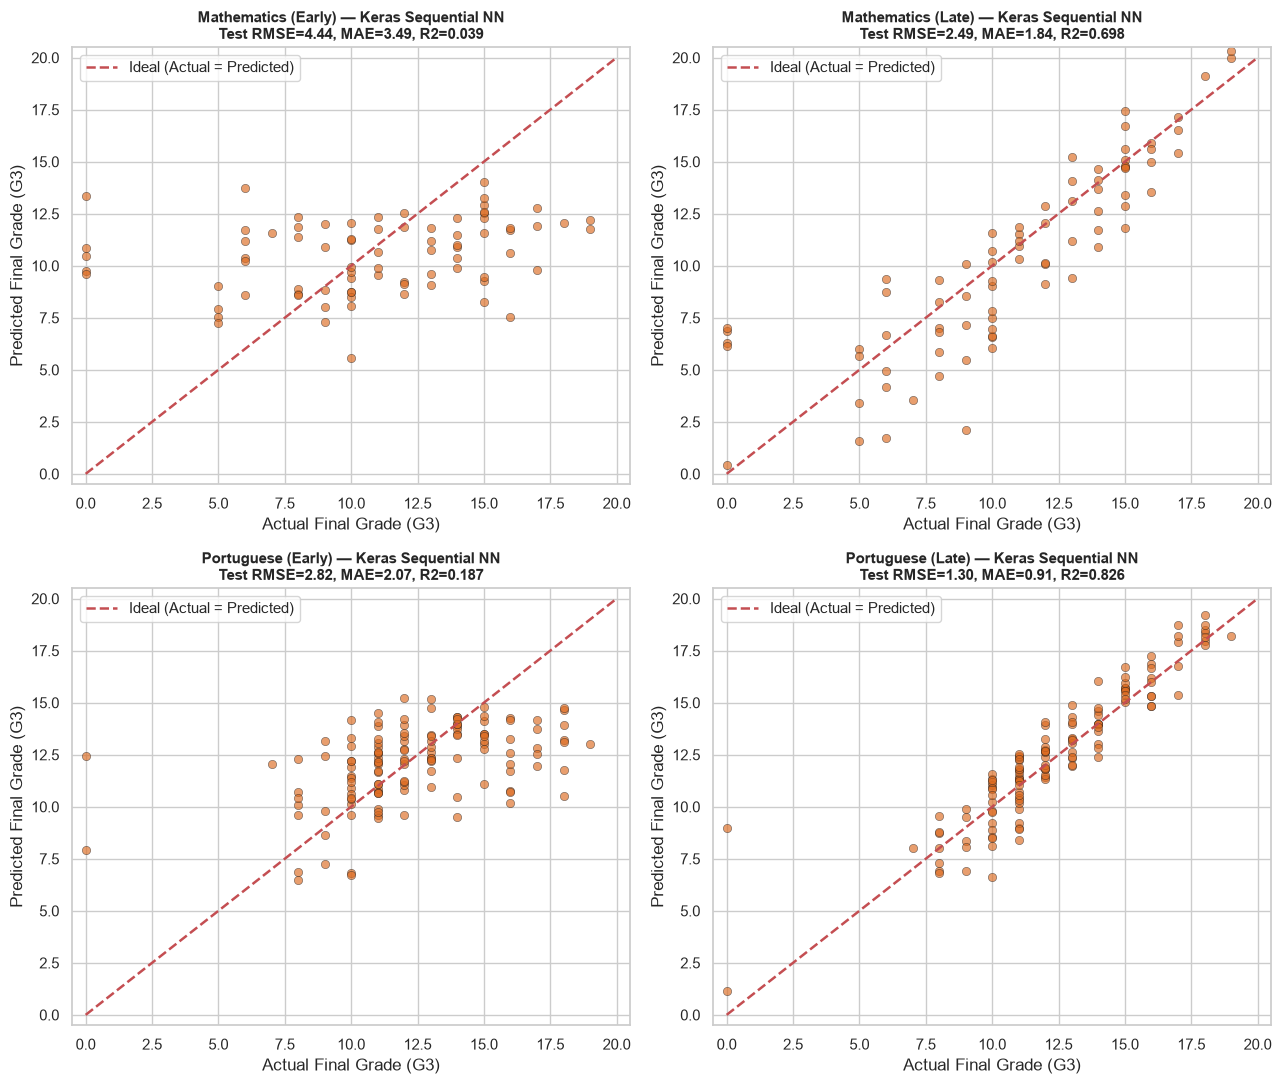

Saved: 14_dl_actual_vs_predicted.png


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.flatten()

for ax, (_, row) in zip(axes, dl_results_df.iterrows()):
    subj, scen = row["Subject"], row["Scenario"]
    y_test = artifacts_store[(subj, scen)]["y_test"]
    y_pred = artifacts_store[(subj, scen)]["test_pred"]

    ax.scatter(y_test, y_pred, alpha=0.65, edgecolors="k", linewidth=0.4, color="#dd6b20")
    ax.plot([0, 20], [0, 20], "r--", linewidth=1.8, label="Ideal (Actual = Predicted)")
    ax.set_title(
        f"{subj} ({scen.title()}) — Keras Sequential NN\n"
        f"Test RMSE={row['Test_RMSE']:.2f}, MAE={row['Test_MAE']:.2f}, R2={row['Test_R2']:.3f}",
        fontsize=11, fontweight="bold"
    )
    ax.set_xlabel("Actual Final Grade (G3)")
    ax.set_ylabel("Predicted Final Grade (G3)")
    ax.set_xlim(-0.5, 20.5)
    ax.set_ylim(-0.5, 20.5)
    ax.legend()

plt.tight_layout()
ap_fig = FIGURES_DIR / "14_dl_actual_vs_predicted.png"
plt.savefig(ap_fig, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", ap_fig.name)

## 6. Save Keras Models (`.keras`), Preprocessors & Evaluation Metrics
We save:
- Each trained Neural Network in `models/` using native Keras `.keras` format
- Each fitted `ColumnTransformer` preprocessor in `models/` so saved `.keras` models can transform raw unseen student rows consistently
- Evaluation CSV and JSON reports in `artifacts/`

In [9]:
dl_summary = []

for _, row in dl_results_df.iterrows():
    subj, scen = row["Subject"], row["Scenario"]
    short_subj = "math" if subj == "Mathematics" else "portuguese"
    model_file = f"{short_subj}_{scen}_nn.keras"
    prep_file = f"{short_subj}_{scen}_nn_preprocessor.joblib"

    model_path = MODELS_DIR / model_file
    prep_path = MODELS_DIR / prep_file

    bundle = artifacts_store[(subj, scen)]
    bundle["model"].save(model_path)
    joblib.dump(bundle["preprocessor"], prep_path)

    dl_summary.append({
        "subject": subj,
        "scenario": scen,
        "model_file": str(model_path.relative_to(PROJECT_ROOT)),
        "preprocessor_file": str(prep_path.relative_to(PROJECT_ROOT)),
        "feature_columns": bundle["feature_columns"],
        "input_dim": int(row["Input_Dim"]),
        "epochs_run": int(row["Epochs_Run"]),
        "best_epoch": int(row["Best_Epoch"]),
        "test_mae": round(float(row["Test_MAE"]), 4),
        "test_rmse": round(float(row["Test_RMSE"]), 4),
        "test_r2": round(float(row["Test_R2"]), 4),
    })
    print(f"Saved: {model_file} + {prep_file}")

dl_eval_csv = ARTIFACTS_DIR / "dl_evaluation_results.csv"
dl_cmp_csv = ARTIFACTS_DIR / "dl_vs_ml_comparison.csv"
dl_sum_json = ARTIFACTS_DIR / "dl_models_summary.json"
dl_meta_json = MODELS_DIR / "dl_model_metadata.json"

dl_results_df.round(4).to_csv(dl_eval_csv, index=False)
comparison_df.drop(columns=["Task"]).round(4).to_csv(dl_cmp_csv, index=False)
dl_sum_json.write_text(json.dumps(dl_summary, indent=2))
dl_meta_json.write_text(json.dumps(dl_summary, indent=2))

print("Saved artifacts:", dl_eval_csv.name, ",", dl_cmp_csv.name, ",", dl_sum_json.name)

Saved: math_early_nn.keras + math_early_nn_preprocessor.joblib
Saved: math_late_nn.keras + math_late_nn_preprocessor.joblib
Saved: portuguese_early_nn.keras + portuguese_early_nn_preprocessor.joblib
Saved: portuguese_late_nn.keras + portuguese_late_nn_preprocessor.joblib
Saved artifacts: dl_evaluation_results.csv , dl_vs_ml_comparison.csv , dl_models_summary.json


## 7. Verify Loading Saved `.keras` Models & Predicting Unseen Samples
We reload each `.keras` model using `keras.models.load_model()` and its saved preprocessor, verify full test-set metrics match, and print predictions on 5 unseen test students.

In [10]:
for item in dl_summary:
    subj, scen = item["subject"], item["scenario"]
    loaded_model = keras.models.load_model(PROJECT_ROOT / item["model_file"])
    loaded_prep = joblib.load(PROJECT_ROOT / item["preprocessor_file"])

    bundle = artifacts_store[(subj, scen)]
    X_test, y_test = bundle["X_test"], bundle["y_test"]

    X_test_arr = loaded_prep.transform(X_test).astype(np.float32)
    full_preds = loaded_model.predict(X_test_arr, verbose=0).ravel()
    check_m = regression_metrics(y_test, full_preds)

    preview = pd.DataFrame({
        "Actual_G3": y_test[:5].astype(int),
        "NN_Predicted_G3": np.round(full_preds[:5], 2),
        "Abs_Error": np.round(np.abs(y_test[:5] - full_preds[:5]), 2),
    }, index=X_test.iloc[:5].index)

    print(
        f"\n=== Reloaded {item['model_file']} | Full Test (n={len(y_test)}): "
        f"MAE={check_m['MAE']:.4f}, RMSE={check_m['RMSE']:.4f}, R2={check_m['R2']:.4f} ==="
    )
    display(preview)


=== Reloaded models/math_early_nn.keras | Full Test (n=79): MAE=3.4899, RMSE=4.4397, R2=0.0387 ===


,Actual_G3,NN_Predicted_G3,Abs_Error
78,10,8.74,1.26
371,12,8.64,3.36
248,5,9.02,4.02
55,10,11.23,1.23
390,9,7.31,1.69



=== Reloaded models/math_late_nn.keras | Full Test (n=79): MAE=1.8380, RMSE=2.4890, R2=0.6979 ===


,Actual_G3,NN_Predicted_G3,Abs_Error
78,10,6.58,3.42
371,12,12.88,0.88
248,5,1.60,3.40
55,10,10.17,0.17
390,9,10.07,1.07



=== Reloaded models/portuguese_early_nn.keras | Full Test (n=130): MAE=2.0679, RMSE=2.8165, R2=0.1865 ===


,Actual_G3,NN_Predicted_G3,Abs_Error
636,19,12.99,6.01
220,12,12.76,0.76
594,18,13.20,4.80
429,11,12.59,1.59
72,11,10.70,0.30



=== Reloaded models/portuguese_late_nn.keras | Full Test (n=130): MAE=0.9147, RMSE=1.3043, R2=0.8255 ===


,Actual_G3,NN_Predicted_G3,Abs_Error
636,19,18.18,0.82
220,12,11.81,0.19
594,18,18.33,0.33
429,11,11.30,0.30
72,11,12.27,1.27


## 8. Overfitting Analysis & Deep Learning Limitations
1. **Small tabular datasets limit Neural Networks:** After reserving `20%` for testing and `20%` of the remainder for validation, each MLP trains on only **`252` rows (Math)** or **`415` rows (Portuguese)** across `40+` one-hot-encoded input features. Deep Neural Networks are high-capacity function approximators that typically need thousands of rows to generalize better than classical tabular models.
2. **Observed overfitting vs EarlyStopping:** Without stopping early, training MSE continues dropping toward zero while validation MSE flattens or climbs; `EarlyStopping(patience=15, restore_best_weights=True)` stops training near the minimum validation loss and restores the best weights.
3. **Fair comparison with Day 3 ML models:** As shown in `artifacts/dl_vs_ml_comparison.csv`, we never assume Neural Networks win automatically — we compare actual test `MAE`, `RMSE`, and `R2` honestly across all four tasks and pick whichever model generalizes best on unseen students.
4. **Linear output layer range:** Because the output layer uses `activation='linear'`, predictions are unbounded real numbers and should be clipped to `[0, 20]` if displayed to end users.